In [2]:
#importer les library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/inclusion-financiere-en-afrique.csv')
df.head()

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [5]:
df.dtypes

,0
country,object
year,int64
uniqueid,object
bank_account,object
location_type,object
cellphone_access,object
household_size,int64
age_of_respondent,int64
gender_of_respondent,object
relationship_with_head,object


In [6]:
df.isnull().sum()

,0
country,0
year,0
uniqueid,0
bank_account,0
location_type,0
cellphone_access,0
household_size,0
age_of_respondent,0
gender_of_respondent,0
relationship_with_head,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 23524 non-null  object
 1   year                    23524 non-null  int64 
 2   uniqueid                23524 non-null  object
 3   bank_account            23524 non-null  object
 4   location_type           23524 non-null  object
 5   cellphone_access        23524 non-null  object
 6   household_size          23524 non-null  int64 
 7   age_of_respondent       23524 non-null  int64 
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
dtypes: int64(3), object(10)
memory usage: 2.3+ MB


In [8]:
df.describe()

,year,household_size,age_of_respondent
count,23524.000000,23524.000000,23524.000000
mean,2016.975939,3.797483,38.805220
std,0.847371,2.227613,16.520569
min,2016.000000,1.000000,16.000000
25%,2016.000000,2.000000,26.000000
50%,2017.000000,3.000000,35.000000
75%,2018.000000,5.000000,49.000000
max,2018.000000,21.000000,100.000000


In [32]:
print(df.columns.tolist())

['year', 'household_size', 'age_of_respondent']


In [33]:
%whos

Variable         Type         Data/Info
---------------------------------------
PCA              ABCMeta      <class 'sklearn.decomposition._pca.PCA'>
StandardScaler   type         <class 'sklearn.preproces<...>ng._data.StandardScaler'>
col_cible        str          bank_account
col_pays         str          country
df               DataFrame                           ye<...>129729           1.000000
df_num           DataFrame                           ye<...>129729           1.000000
drive            module       <module 'google.colab.dri<...>s/google/colab/drive.py'>
np               module       <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
pd               module       <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
plt              module       <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
sns              module       <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>


In [34]:
print(df_num.columns.tolist())

['year', 'household_size', 'age_of_respondent']


In [35]:
import glob

fichiers = glob.glob('/content/drive/MyDrive/**/inclusion-financiere-en-afrique.csv', recursive=True)
print(fichiers)

['/content/drive/MyDrive/inclusion-financiere-en-afrique.csv', '/content/drive/MyDrive/AIMS-Module5_DS_ML_Oct-Nov-2026/inclusion-financiere-en-afrique.csv']


In [37]:
df = pd.read_csv('/content/drive/MyDrive/inclusion-financiere-en-afrique.csv')

print(df.columns.tolist())

['country', 'year', 'uniqueid', 'bank_account', 'location_type', 'cellphone_access', 'household_size', 'age_of_respondent', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']


In [39]:

# Taux global
taux_global = (df["bank_account"].str.strip().str.lower() == "yes").mean() * 100

# Taux par pays
taux_pays = (
    df.assign(bancarise=df["bank_account"].str.strip().str.lower() == "yes")
      .groupby("country")["bancarise"]
      .mean() * 100
)

print(f"Taux global : {taux_global:.2f}%")
print("\nTaux par pays :")
print(taux_pays.sort_values(ascending=False).round(2))

Taux global : 14.08%

Taux par pays :
country
Kenya       25.07
Rwanda      11.48
Tanzania     9.17
Uganda       8.61
Name: bancarise, dtype: float64


Répartition des observations par pays et par année :


year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


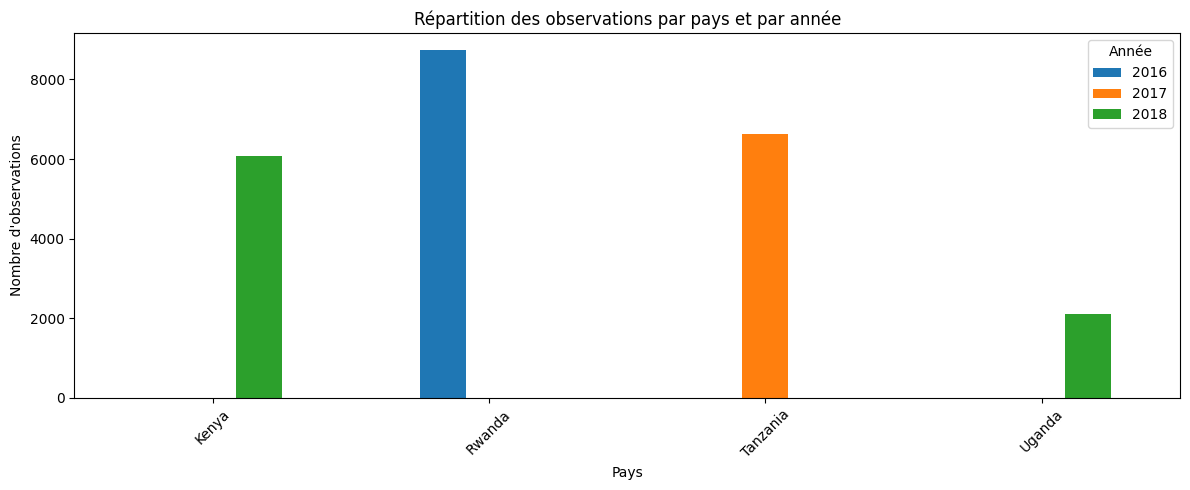

In [40]:
# Croisement entre country et year
table = pd.crosstab(df["country"], df["year"])

# Affichage du tableau
print("Répartition des observations par pays et par année :")
display(table)

# Visualisation
table.plot(kind="bar", figsize=(12, 5))

plt.title("Répartition des observations par pays et par année")
plt.xlabel("Pays")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45)
plt.legend(title="Année")
plt.tight_layout()
plt.show()

In [41]:
# Identifier les variables catégorielles
colonnes_cat = df.select_dtypes(include=["object"]).columns

# Rechercher les modalités ayant moins de 50 occurrences
for col in colonnes_cat:
    rares = df[col].value_counts()[df[col].value_counts() < 50]

    if not rares.empty:
        print(f"\n{col} :")
        print(rares)


uniqueid :
uniqueid
uniqueid_17      4
uniqueid_16      4
uniqueid_18      4
uniqueid_2       4
uniqueid_3       4
                ..
uniqueid_7303    1
uniqueid_7302    1
uniqueid_7301    1
uniqueid_7300    1
uniqueid_7308    1
Name: count, Length: 8735, dtype: int64

marital_status :
marital_status
Dont know    8
Name: count, dtype: int64

education_level :
education_level
Other/Dont know/RTA    35
Name: count, dtype: int64


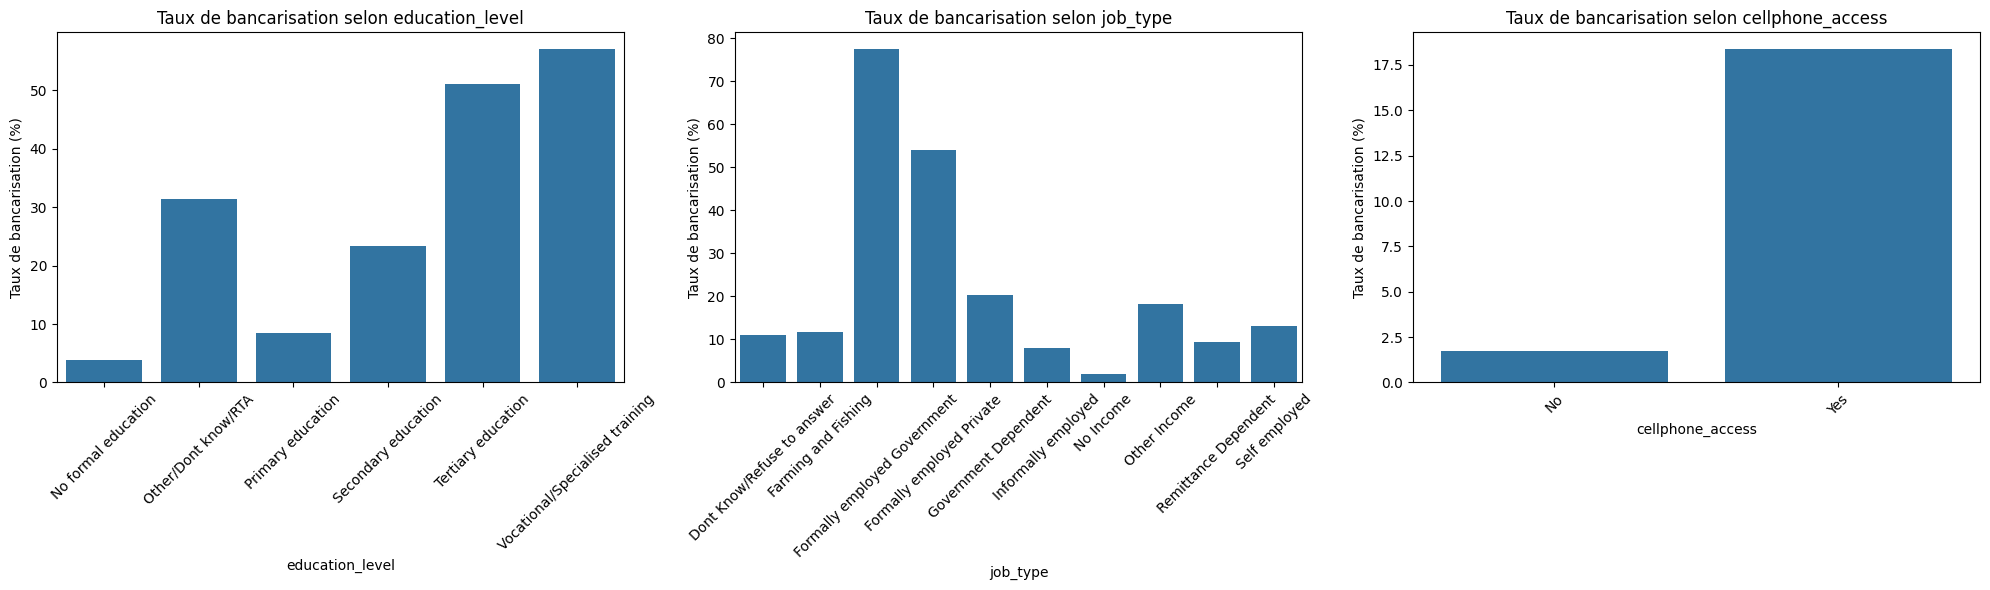

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = ["education_level", "job_type", "cellphone_access"]

# Transformer bank_account en variable binaire
df["bancarise"] = (
    df["bank_account"].astype(str).str.strip().str.lower() == "yes"
).astype(int)

# Tracer les trois graphiques
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, variable in zip(axes, variables):
    taux = df.groupby(variable)["bancarise"].mean() * 100

    sns.barplot(
        x=taux.index,
        y=taux.values,
        ax=ax
    )

    ax.set_title(f"Taux de bancarisation selon {variable}")
    ax.set_xlabel(variable)
    ax.set_ylabel("Taux de bancarisation (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()